# Modulación LoRa (FSCM)

Modelo en Python de la modulación LoRa basado en el análisis de
L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960),
*IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |

## Modelo del sistema

*TODO(b-Tomas): diagrama de bloques*

In [2]:
# Todos los imports van acá
import matplotlib.pyplot as plt
import numpy as np
from math import sqrt

## Transmisión

El módulo transmisor se compone de dos partes: el codificador y el conformador de onda.

### Codificador

Se considera como objetivo transmitir y recibir un conjunto de bits. Para esto, se debe convertir el conjunto de bits en símbolos.

El bloque de parámetros ya define los símbolos a enviar en la lista `symbols`, por lo que primero se retrocederá un paso para convetirlos en el conjunto de bits a enviar. Luego, `encoder()` tomará el conjunto de bits y los convertirá en símbolos.

Cada símbolo se genera con un vector $w(nT_s)$ de $SF$ bits de acuerdo a Ec. 1:

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

$w_0$ es el bit menos significativo. El flujo de bits se corta en grupos de $SF$ bits, un grupo por símbolo.

In [3]:
def encoder(bits: np.ndarray, SF: int) -> np.ndarray:
    """Convierte un conjunto de bits en símbolos.

    Organiza `bits` en grupos $w(nT_s)$ de `SF` bits y los convierte a símbolos.

    Args:
        bits (np.ndarray): Conjunto de bits a transmitir.
        SF (int): Spreading factor.

    Returns:
        np.ndarray: Conjunto de símbolos a transmitir.
    """

    # Validar la forma del vector de bits a enviar
    assert bits.size % SF == 0, "El número de bits debe ser múltiplo de SF"

    # Reorganizar los bits en grupos de SF bits
    # El resultado es un arreglo de forma (N, SF) donde N es el número de símbolos.
    # Cada símbolo es un vector equivalente a $w(nT_s)$
    W = bits.reshape(-1, SF)

    # Secuencia h = 0..SF-1
    h = np.arange(SF)

    # Convertir cada grupo de SF bits a un símbolo
    # 2**h produce un vector de potencias de 2: [1, 2, 4, ..., 2**(SF-1)]
    # W @ 2**h realiza el producto matricial, sumando los productos de cada bit por su correspondiente potencia de 2.
    return W @ 2**h

In [4]:
# Tests
assert np.array_equal(encoder(np.array([0, 0, 0, 1, 0, 0, 0]), 7), np.array([8]))
assert np.array_equal(
    encoder(np.array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]), 7), np.array([8, 127])
)

### Conformador de onda

Dado el vector de símbolos $s(nT_s)$, el conformador de onda genera la señal modulada de acuerdo a Ec. 2 para cada símbolo $n$ y cada chip $k = 0, \dots, 2^{SF}-1$:

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[(s(nT_s) + k) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

In [5]:
def modulator(symbols: np.ndarray, SF: int, B: float) -> np.ndarray:
    """Genera la forma de onda FSCM para una secuencia de símbolos.

    Muestrea a k = 0..2**SF-1 chips por cada símbolo n.

    Args:
        symbols (np.ndarray): Conjunto de símbolos $s(nT_s)$ a transmitir. 0 <= s < 2**SF.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.

    Returns:
        np.ndarray: Señal modulada (compleja) en el dominio del tiempo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Tiempo de chip
    T = 1 / B

    # Convertir s a un vector de forma (N, 1) para poder sumarle k
    s = symbols.reshape(-1, 1)  # Vector columna de símbolos

    # Vector de chips k = 0..M-1
    k = np.arange(M)  # Vector fila de chips

    # Frecuencia instantanea de la señal modulada: f(k) = (s + k) mod M * B / M
    # Es el exponente en la Ec. 2, sin el muestreo kT
    f = ((s + k) % M) * B / M

    # c[n, k] = c(nT_s + kT). Vector de forma (N, M) donde N es el número de símbolos y M es el número de chips por símbolo.
    c = np.exp(1j * 2 * np.pi * f * k * T) / np.sqrt(M)

    return c.ravel()  # Aplanar a un vector unidimensional de chips

#### Análisis de la señal modulada

Antes de continuar con la transmisión, se analiza la forma y comportamiento de la señal modulada en tiempo y en frecuencia en una configuración con *Spreading Factor* de 7.

In [6]:
SF = 7
symbols = np.array([0, 32, 80])
B = 125e3  # Ancho de banda de 125 kHz

c = modulator(symbols, SF, B)

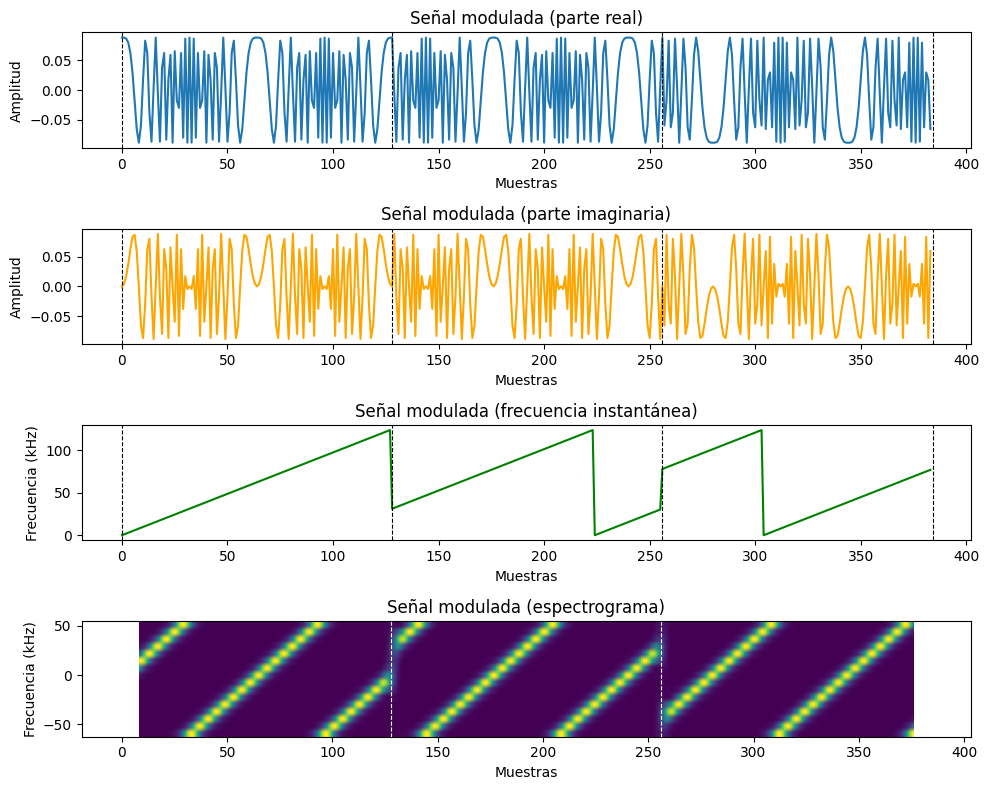

In [7]:
# Señal real e imaginaria de la señal modulada en el tiempo
plt.figure(figsize=(10, 8))
plt.subplot(4, 1, 1)
plt.plot(np.real(c), label="Real")
plt.title("Señal modulada (parte real)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.subplot(4, 1, 2)
plt.plot(np.imag(c), label="Imag", color="orange")
plt.title("Señal modulada (parte imaginaria)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
# Frecuencia instantánea en el tiempo: f(k) = (s + k) mod M * B / M
plt.subplot(4, 1, 3)
k = np.arange(2**SF)
f = ((symbols.reshape(-1, 1) + k) % 2**SF) * B / 2**SF
plt.plot(f.ravel() / 1e3, color="green")
plt.title("Señal modulada (frecuencia instantánea)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
# Espectrograma: frecuencia en el tiempo estimada a partir de la señal c
plt.subplot(4, 1, 4)
N = 16  # muestras por ventana de la FFT
# xextent: eje x en muestras, como los otros gráficos (cada ventana se ubica en su centro)
plt.specgram(
    c,
    NFFT=N,
    noverlap=N - 1,
    Fs=B / 1e3,
    sides="twosided",
    scale="linear",
    xextent=(N / 2, c.size - N / 2),
)
plt.title("Señal modulada (espectrograma)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
# Separación entre símbolos: un símbolo (Ts) son 2**SF muestras
for ax in plt.gcf().axes:
    for n in range(len(symbols) + 1):
        # Blanco sobre el espectrograma (fondo oscuro), negro en el resto
        ax.axvline(n * 2**SF, color="w" if ax.images else "k", ls="--", lw=0.8)
plt.tight_layout()
plt.show()

**Dominio del tiempo**:
- La señal es una exponencial compleja de frecuencia variable, conocida como *chirp*.
- La parte real es una onda cosenoidal de frecuencia creciente, mientras que la parte imaginaria es una onda senoide de frecuencia creciente.

**Frecuencia instantánea**:
- El gráfico muestra la frecuencia instantánea de la señal de la Ec. 2. con fines pedagógicos.
- De acuerdo con lo que se puede ver en las ondas de la parte real e imaginaria, la frecuencia instantánea es una función lineal del tiempo, que aumenta de 0 a $B$ en el intervalo de tiempo $T_s$.
- La frecuencia instantánea inicial para cada símbolo es distinta de acuerdo a $f_0 = \frac{B}{2^{SF}} s(nT_s)$.

**Espectrograma:**
- Muestra la frecuencia real de $c$.

## Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas, y genera símbolos a partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

Se analizará primero demodulando la señal modulada, y luego sumándole ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

El proceso de demodulación de forma computacionalmente eficiente se describe en Ec. 16 como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{q}$:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j2\pi \frac{k^2}{2^{SF}}} \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

Se puede interpretar como la correlación entre la señal recibida y todos los *chirps* posibles, siendo el *chirp* que maximiza la proyección el símbolo recibido.

El término $e^{-j2\pi \frac{k^2}{2^{SF}}}$ se conoce como *down-chirp*. El resultado $d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j2\pi \frac{k^2}{2^{SF}}}$ es una exponencial compleja de frecuencia constante igual a la frecuencia inicial del símbolo recibido. Se utiliza la transformada rápida de Fourier (FFT).

Luego, la transformada de Fourier de $d(nT_s + kT)$ resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.


In [8]:
def demodulator(r: np.ndarray, SF: int) -> np.ndarray:
    """Demodula una señal LoRa de Spreading-Factor SF según Ec. 16.

    Args:
        r: Señal LoRa modulada recibida.
        SF: Spreading-Factor.

    Returns:
        np.ndarray: Arreglo unidimensional de símbolos demodulados.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Validar el largo del array
    assert r.size % M == 0, "El número de chirps debe ser múltiplo de SF"

    # Convertir s a un vector de forma (N, M): R[n, k] = r(nT_s + kT)
    R = r.reshape(-1, M)  # Vector columna de símbolos

    # Vector de chips k = 0..M-1
    k = np.arange(M)  # Vector fila de chips

    # Obtener d(nT_s + kT) = r(nT_s + kT) * downchirp
    downchirp = np.exp(-1j * 2 * np.pi * k**2 / M)
    d = R * downchirp

    # Transformada de Fourier (discreta) de cada fila (símbolo)
    # norm="ortho" normaliza la FFT para que la salida sea unitiaria (conserve la energía de la señal)
    # equivalente a aplicar el factor 1/sqrt(M) de Ec. 16 a la salida de la FFT
    D = np.fft.fft(d, norm="ortho")

    # Decidir el símbolo demodulado como el índice del máximo de la FFT
    return np.argmax(np.abs(D) ** 2, axis=1)

In [9]:
# Tests
assert np.array_equal(demodulator(modulator(symbols, SF, B), SF), symbols)

#### Visualización del proceso de decisión

Para cada símbolo recibido se obtiene la frecuencia inicial del *chirp* recibido mediante el *down-chirp* y la FFT. La transformada de Fourier de $d(nT_s + kT)$ (una exponencial compleja de frecuencia constante) resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.

Mas adelante se analizará la decisión en un canal ruidoso.

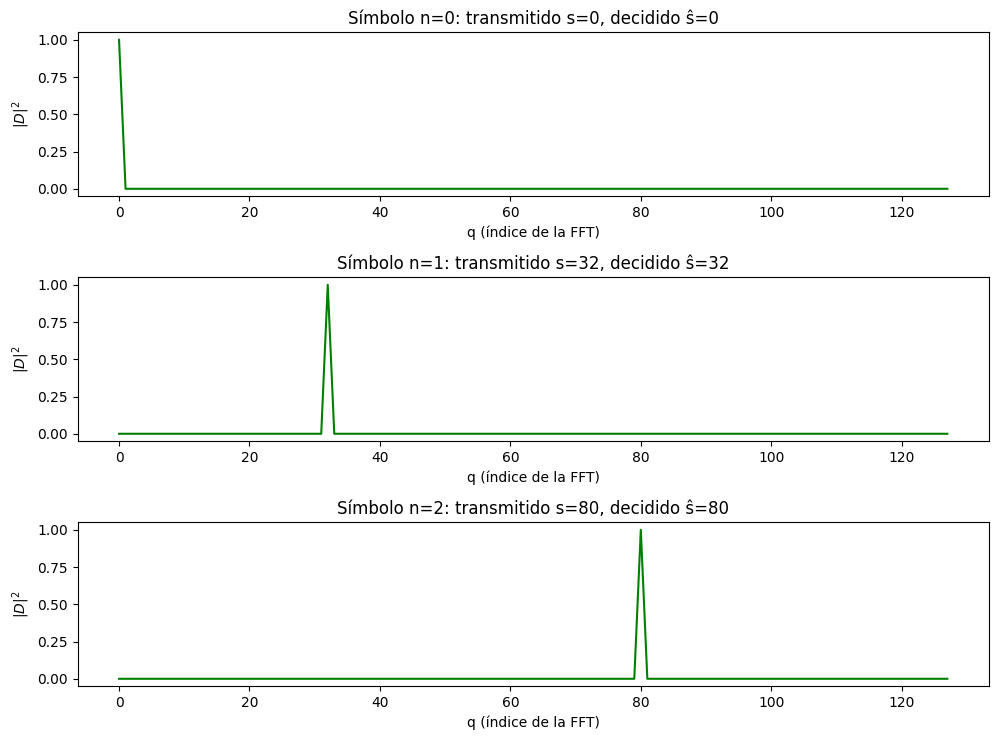

In [10]:
# Repetir los pasos de demodulator para ver la salida de la FFT antes de decidir
M: int = 2**SF
k = np.arange(M)
# Multiplicar cada símbolo recibido por el down-chirp
d = c.reshape(-1, M) * np.exp(-1j * 2 * np.pi * k**2 / M)
# FFT de cada símbolo
D = np.fft.fft(d, norm="ortho")
# Decisión: índice del máximo de |D|^2
symbols_rx = demodulator(c, SF)

plt.figure(figsize=(10, 2.5 * len(symbols)))
for n in range(len(symbols)):
    plt.subplot(len(symbols), 1, n + 1)
    plt.plot(np.abs(D[n]) ** 2, color="green")
    plt.title(f"Símbolo n={n}: transmitido s={symbols[n]}, decidido ŝ={symbols_rx[n]}")
    plt.xlabel("q (índice de la FFT)")
    plt.ylabel("$|D|^2$")
plt.tight_layout()
plt.show()

### Decodificación

Se descompone cada símbolo en un arreglo de $SF$ bits de acuerdo a Ec. 1.

In [11]:
def decoder(symbols: np.ndarray, SF: int) -> np.ndarray:
    """Convierte un conjunto de símbolos en bits.

    Descompone cada símbolo en un arreglo de `SF` bits de acuerdo a Ec. 1.

    Args:
        symbols (np.ndarray): Conjunto de símbolos a decodificar.
        SF (int): Spreading factor.

    Returns:
        np.ndarray: Conjunto de bits decodificados.
    """

    # Convertir los símbolos a un arreglo columna de forma (N, 1) para poder resolver como
    # una operación matricial
    s = symbols.reshape(-1, 1)  # Vector columna de símbolos

    # Secuencia h = 0..SF-1
    h = np.arange(SF)

    # Expande cada vector de un símbolo a un arreglo de SF bits
    # Se desplaza el símbolo h veces a la derecha para cada valor de h, para cada símbolo
    # Nos quedamos con el bit menos significativo
    W = (s >> h) & 1

    # Aplanar a un vector unidimensional de bits
    return W.ravel()

In [12]:
# Tests
assert np.array_equal(decoder(np.array([8]), 7), np.array([0, 0, 0, 1, 0, 0, 0]))
assert np.array_equal(
    decoder(np.array([8, 127]), 7), np.array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1])
)

## Cálculo del Bit Error Rate (BER)

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

Ya que aún no hemos introducido ruido en el canal, esperamos que el BER sea 0.

In [13]:
def BER(bits_tx: np.ndarray, bits_rx: np.ndarray) -> float:
    """Calcula el Bit Error Rate (BER) comparando los bits transmitidos y recibidos.

    Args:
        bits_tx (np.ndarray): Conjunto de bits transmitidos.
        bits_rx (np.ndarray): Conjunto de bits recibidos.

    Returns:
        float: Bit Error Rate (BER).
    """

    # Validar que ambos conjuntos de bits tengan la misma longitud
    assert bits_tx.size == bits_rx.size, "Los conjuntos de bits deben tener la misma longitud"

    # Obtener los bits erróneos con un XOR entre los bits transmitidos y recibidos
    return sum(bits_tx ^ bits_rx) / bits_tx.size

In [14]:
# Simular una transmisión completa
SF = 7
B = 125e3
# Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
bits_tx = np.random.randint(0, 2, size=SF * 100)
bits_rx = decoder(demodulator(modulator(encoder(bits_tx, SF), SF, B), SF), SF)  # Bits recibidos
ber = BER(bits_tx, bits_rx)  # Calcular el BER
print(f"Bit Error Rate (BER): {ber:.4f}")

# En caso de corromper un bit:
bits_rx[0] ^= 1  # bit flip
print(f"Bit Error Rate (BER) con un bit corrupto: {BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


## Potencia de la señal modulada

In [15]:
def power(c: np.ndarray) -> float:
    """Calcula la potencia de la señal modulada.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.

    Returns:
        float: Potencia de la señal modulada.
    """

    # La potencia de una señal compleja es el valor medio de su magnitud al cuadrado
    return np.mean(np.abs(c) ** 2)

In [16]:
# Simular una transmisión completa
SF = 7
B = 125e3
# Conjunto de 100 símbolos aleatorios
symbols_tx = np.random.randint(0, 2**SF, size=100)
print(
    f"Potencia de la señal modulada con SF={SF}, B={B}kHz: {power(modulator(np.array([0]), SF, B)):.4f}"
)

SF = 2  # type: ignore
print(
    f"Potencia de la señal modulada con SF={SF}, B={B}kHz: {power(modulator(np.array([0]), SF, B)):.4f}"
)

Potencia de la señal modulada con SF=7, B=125000.0kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125000.0kHz: 0.2500


## Modelo de canal ruidoso

El canal dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y desplazamiento. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

In [17]:
def noise_from_SNR(c: np.ndarray, SNR_dB: float) -> np.ndarray:
    """Genera ruido blanco gaussiano aditivo (AWGN) a partir de la señal modulada y la relación señal-ruido (SNR) que se quiera simular.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.
        SNR_dB (float): Relación señal-ruido en decibelios.

    Returns:
        np.ndarray: Señal con ruido aditivo.
    """
    # Convertir SNR de dB a lineal
    SNR_linear = 10 ** (SNR_dB / 10)

    # Calcular la potencia de la señal
    signal_power = power(c)

    # Calcular la potencia del ruido: SNR = signal_power / noise_power => noise_power = signal_power / SNR
    z_power = signal_power / SNR_linear

    # La potencia del ruido gaussiano es igual a la varianza de la distribución normal
    # Se divide la potencia a partes iguales entre la parte real e imaginaria del ruido complejo
    # La desviación estándar es la raíz cuadrada de la varianza
    component_sigma = np.sqrt(z_power / 2)

    # Generar ruido blanco gaussiano.
    # Tiene que ser una exponencial compleja, por lo que se genera ruido para la parte real e imaginaria.
    z = np.random.normal(0, component_sigma, c.shape) + 1j * np.random.normal(
        0, component_sigma, c.shape
    )

    return z

In [18]:
def system(c: np.ndarray, h: np.ndarray, z: np.ndarray) -> np.ndarray:
    """Simula la transmisión de la señal modulada a través de un canal ruidoso.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.
        h (np.ndarray): Respuesta al impulso del canal.
        z (np.ndarray): Ruido blanco gaussiano aditivo (AWGN).

    Returns:
        np.ndarray: Señal recibida después de pasar por el canal ruidoso.
    """
    # Convolución de la señal modulada con la respuesta al impulso del canal
    # mode="same" asegura que la salida tenga el mismo tamaño que la señal de entrada
    c_channel = np.convolve(c, h, mode="same")

    # Sumar el ruido a la señal distorsionada por el canal
    return c_channel + z

In [19]:
def simulation(SF: int, B: float, SNR_dB: float, h: np.ndarray, num_symbols: int = 100) -> float:
    """Simula la transmisión de una señal LoRa a través de un canal ruidoso y calcula el BER.

    Args:
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        SNR_dB (float): Relación señal-ruido en decibelios.
        h (np.ndarray): Respuesta al impulso del canal.

    Returns:
        float: Bit Error Rate (BER) de la transmisión simulada.
    """
    # Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
    bits_tx = np.random.randint(0, 2, size=SF * num_symbols)

    # Transmisión completa
    c = modulator(encoder(bits_tx, SF), SF, B)  # Señal modulada
    z = noise_from_SNR(c, SNR_dB)  # Ruido generado a partir de la señal y el SNR
    r = system(c, h, z)  # Señal recibida después del canal ruidoso

    # Demodulación y decodificación
    bits_rx = decoder(demodulator(r, SF), SF)

    # Calcular el BER
    return BER(bits_tx, bits_rx)

In [20]:
# Parámetros de la simulación
SF = 7
B = 125e3
h_flat = np.array([1.0])  # Respuesta al impulso neutra
SNR_dB = -10

# Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
bits_tx = np.random.randint(0, 2, size=SF * 100)

# Simular una transmisión completa
ber = simulation(SF, B, SNR_dB, h_flat)
print(f"Bit Error Rate (BER) con SNR={SNR_dB}dB: {ber:.4f}")

Bit Error Rate (BER) con SNR=-10dB: 0.0071


### Detección con ruido en un canal plano

Se repite la simulación de la transmisión y recepción de símbolos, pero esta vez se introduce ruido blanco gaussiano aditivo (AWGN) en el canal.

El canal es plano, es decir, respuesta en frecuencia constante.

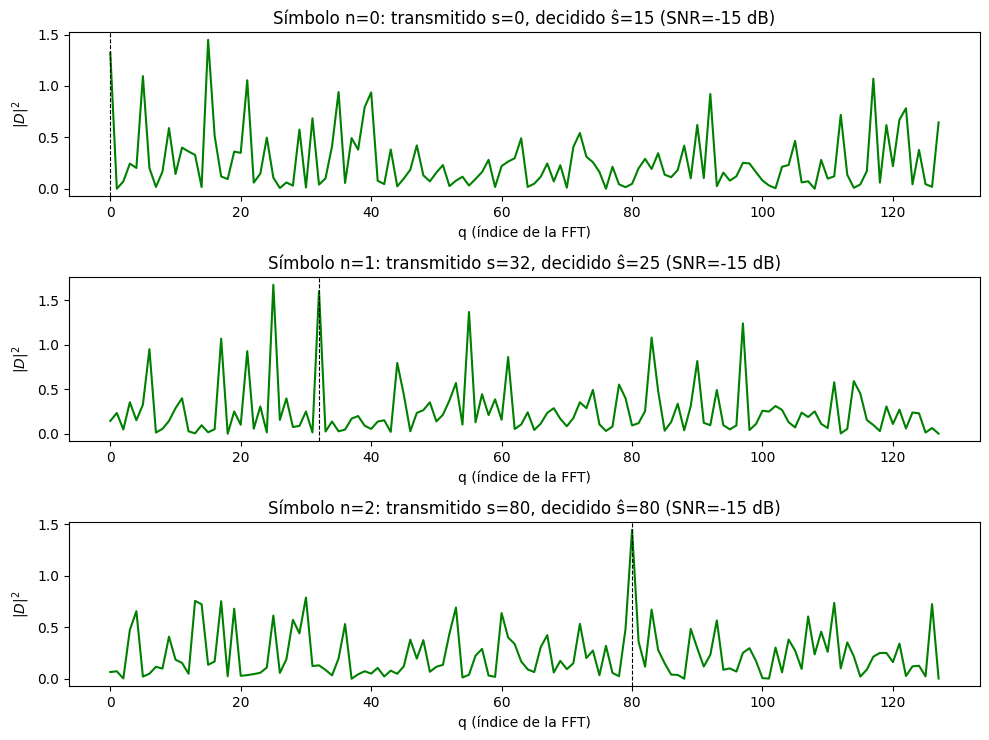

In [21]:
# Parámetros: probar distintos SNR para ver cuándo empieza a fallar la decisión
SF = 7
B = 125e3
symbols = np.array([0, 32, 80])
h_flat = np.array([1.0])  # Respuesta al impulso neutra
SNR_dB = -15

# Transmisión a través del canal ruidoso
c = modulator(symbols, SF, B)
z = noise_from_SNR(c, SNR_dB)
r = system(c, h_flat, z)

# Repetir los pasos de demodulator para ver la salida de la FFT antes de decidir
M: int = 2**SF
k = np.arange(M)
# Multiplicar cada símbolo recibido por el down-chirp
d = r.reshape(-1, M) * np.exp(-1j * 2 * np.pi * k**2 / M)
# FFT de cada símbolo
D = np.fft.fft(d, norm="ortho")
# Decisión: índice del máximo de |D|^2
symbols_rx = demodulator(r, SF)

plt.figure(figsize=(10, 2.5 * len(symbols)))
for n in range(len(symbols)):
    plt.subplot(len(symbols), 1, n + 1)
    plt.plot(np.abs(D[n]) ** 2, color="green")
    # Símbolo transmitido, para comparar con el pico
    plt.axvline(symbols[n], color="k", ls="--", lw=0.8)
    plt.title(
        f"Símbolo n={n}: transmitido s={symbols[n]}, decidido ŝ={symbols_rx[n]} (SNR={SNR_dB} dB)"
    )
    plt.xlabel("q (índice de la FFT)")
    plt.ylabel("$|D|^2$")
plt.tight_layout()
plt.show()

### Detección con ruido en un canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia. La respuesta al impulso del sistema usado para modelar un canal multicaminos es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$



### Performance de detección

Se analiza el BER vs SNR para el sistema simulado, el cual corresponde a la curva "Flat FSCM" de Fig. 1.

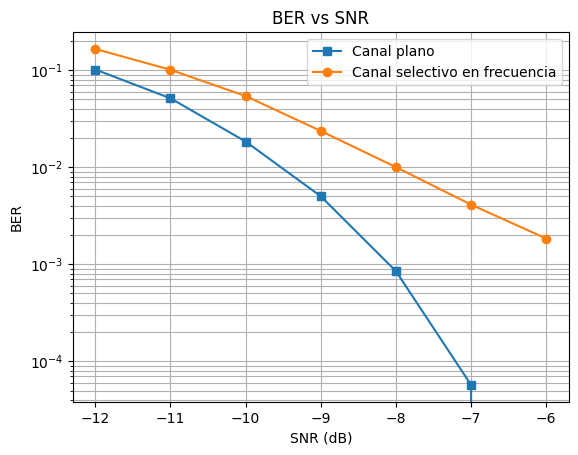

In [22]:
SF = 7
B = 125e3
h_flat = np.array([1.0])  # Canal plano (solo AWGN)
h_freq_sel = np.array([sqrt(0.8), sqrt(0.2)])
SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -5 dB
num_symbols = 100  # Número de símbolos por simulación
simulations = 500  # Cantidad de simulaciones

# 300 simulaciones de 700 bits por punto con canal plano
bers_flat = [
    np.mean([simulation(SF, B, SNR_dB, h_flat) for _ in range(simulations)]) for SNR_dB in SNRs_dB
]
# 300 simulaciones de 700 bits por punto con canal selectivo en frecuencia
bers_freq_sel = [
    np.mean([simulation(SF, B, SNR_dB, h_freq_sel) for _ in range(simulations)])
    for SNR_dB in SNRs_dB
]

plt.semilogy(SNRs_dB, bers_flat, marker="s", label="Canal plano")
plt.semilogy(SNRs_dB, bers_freq_sel, marker="o", label="Canal selectivo en frecuencia")
plt.title("BER vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.grid(True, which="both")
plt.legend()
plt.show()

## Detección de una trama

En esta sección se analiza el problema de la detección de una trama de datos en un canal ruidoso por el lado del receptor. En un inicio se asume que el receptor conoce el instante de tiempo en que comienza la transmisión de datos, por lo que no se habla de sincronización.

Para evaluar la detección de la trama, se enviará un paquete de datos arbitrario con un preámbulo de ocho símbolos `0` y 2.25 downchirps. Luego se decodificarán los símbolos recibidos y se evaluará el rendimiento del receptor calculando el PER (paquet error rate) de la transmisión.

Se plantean una detección en el tiempo y otra en frecuencia

Notas para cuando hagamos con sincronizacion:
- Dejar un espacio en blanco antes de la transmisión, para dar incertidumbre al inicio de la simulación
- Diseñar el receptor para detectar el preámbulo y sincronizar la transmisión de datos
- Decodificar los símbolos recibidos y calcular el PER de la transmisión

In [23]:
def preamble(SF: int, B: float, n_upchirps: int = 8, n_downchirps: float = 2.25) -> np.ndarray:
    """Genera el preámbulo de una trama LoRa.

    El preámbulo se compone de `n_upchirps` up-chirps (símbolos 0) seguidos de `n_downchirps`
    down-chirps, que marcan el fin del preámbulo.

    Args:
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        n_upchirps (int): Cantidad de up-chirps.
        n_downchirps (float): Cantidad de down-chirps. Puede ser fraccionaria.

    Returns:
        np.ndarray: Preámbulo modulado (complejo) en el dominio del tiempo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Up-chirps: símbolos 0 modulados
    upchirps = modulator(np.zeros(n_upchirps, dtype=int), SF, B)

    # Down-chirps: conjugado de un up-chirp (frecuencia instantánea decreciente)
    # Se generan los down-chirps completos necesarios y se recorta la fracción sobrante
    n_full = int(np.ceil(n_downchirps))
    downchirps = np.conj(modulator(np.zeros(n_full, dtype=int), SF, B))[: int(n_downchirps * M)]

    return np.concatenate([upchirps, downchirps])


def transmit_frame(
    symbols: np.ndarray, gap: int, SF: int, B: float, SNR_dB: float, h: np.ndarray
) -> np.ndarray:
    """Simula la transmisión de una trama a través de un canal ruidoso.

    La trama es el preámbulo seguido de los símbolos del payload. Antes de la trama, el receptor
    escucha `gap` símbolos de solo ruido, por lo que no sabe en qué símbolo empieza la trama.

    Args:
        symbols (np.ndarray): Símbolos del payload.
        gap (int): Cantidad de símbolos de silencio antes de la trama.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        SNR_dB (float): Relación señal-ruido en decibelios, respecto de la potencia de la trama.
        h (np.ndarray): Respuesta al impulso del canal.

    Returns:
        np.ndarray: Señal recibida después del canal ruidoso.
    """

    # Chips por símbolo
    M: int = 2**SF

    frame = np.concatenate([preamble(SF, B), modulator(symbols, SF, B)])

    # Silencio antes de la trama: el transmisor no emite nada
    c = np.concatenate([np.zeros(gap * M), frame])

    # El SNR se define respecto de la potencia de la trama, no del silencio
    # np.resize repite la trama hasta el largo de c: misma potencia y misma forma que c
    z = noise_from_SNR(np.resize(frame, c.size), SNR_dB)

    return system(c, h, z)

In [24]:
# Tests
assert preamble(7, 125e3).size == 8 * 2**7 + 9 * 2**7 // 4

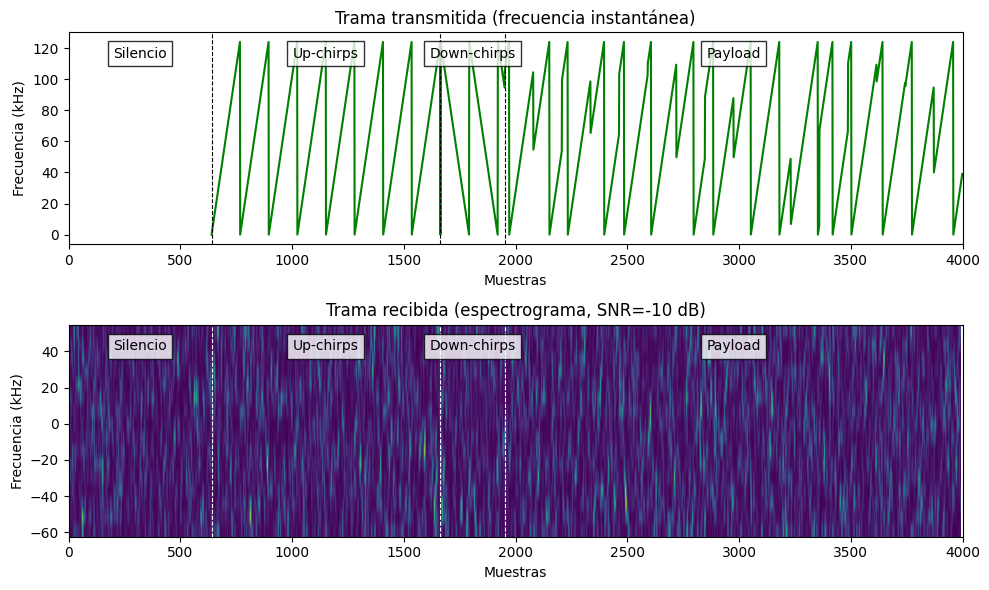

In [25]:
# Escenario para analizar las dos estrategias de detección
SF = 7
B = 125e3
M = 2**SF
SNR_dB = -10
gap = 5  # Símbolos de silencio antes de la trama: desconocido para el receptor
h_flat = np.array([1.0])  # Canal plano (solo AWGN)
symbols_tx = np.random.randint(0, M, size=16)  # Símbolos del payload

r = transmit_frame(symbols_tx, gap, SF, B, SNR_dB, h_flat)

# Potencia del ruido por muestra (sigma^2). Se asume que el receptor la conoce: en la práctica se
# estima mientras no hay señal
noise_power = power(preamble(SF, B)) / 10 ** (SNR_dB / 10)

# Estructura de la trama recibida: frecuencia instantánea sin ruido (arriba, con fines pedagógicos
# como en el análisis de la señal modulada) y espectrograma de la señal recibida (abajo)
# Con SNR negativo la trama no se distingue a simple vista en el espectrograma: hace falta un detector
k = np.arange(M)
f_up = k * B / M  # Up-chirp (símbolo 0): de 0 a B
f_down = ((M - k) % M) * B / M  # Down-chirp: de B a 0
f_payload = ((symbols_tx.reshape(-1, 1) + k) % M) * B / M  # Ec. 2 para cada símbolo del payload
f = np.concatenate(
    [
        np.full(gap * M, np.nan),  # Silencio: no hay señal
        np.tile(f_up, 8),
        np.tile(f_down, 3)[: 9 * M // 4],
        f_payload.ravel(),
    ]
)

# Límites entre partes de la trama y nombre de cada parte
bounds = [0, gap * M, (gap + 8) * M, (gap + 8) * M + 9 * M // 4, r.size]
names = ["Silencio", "Up-chirps", "Down-chirps", "Payload"]

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(f / 1e3, color="green")
plt.title("Trama transmitida (frecuencia instantánea)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
plt.subplot(2, 1, 2)
N = 16  # muestras por ventana de la FFT
plt.specgram(
    r,
    NFFT=N,
    noverlap=N - 1,
    Fs=B / 1e3,
    sides="twosided",
    scale="linear",
    xextent=(N / 2, r.size - N / 2),
)
plt.title(f"Trama recibida (espectrograma, SNR={SNR_dB} dB)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
for ax in plt.gcf().axes:
    for x in bounds[1:-1]:
        # Blanco sobre el espectrograma (fondo oscuro), negro en el resto
        ax.axvline(x, color="w" if ax.images else "k", ls="--", lw=0.8)
    # Nombre de cada parte, centrado entre sus límites (x en muestras, y relativo al gráfico)
    for left, right, name in zip(bounds[:-1], bounds[1:], names):
        ax.text(
            (left + right) / 2,
            0.88,
            name,
            ha="center",
            transform=ax.get_xaxis_transform(),
            bbox=dict(facecolor="w", alpha=0.8),
        )
    ax.set_xlim(0, r.size)  # Mismo eje en ambos gráficos, incluyendo el silencio
plt.tight_layout()
plt.show()

### Detección en el tiempo

Se asume sincronía de símbolo: el receptor divide la señal recibida en ventanas de $2^{SF}$ muestras alineadas con los bordes de los símbolos. Lo que no conoce es en qué ventana empieza la trama, ya que antes de ella solo recibe ruido.

Para cada ventana $m$ se plantea un test de hipótesis binario:

- $H_0$: el preámbulo no empieza en la ventana $m$. Se recibe solo ruido, u otra parte de la trama.
- $H_1$: el preámbulo empieza en la ventana $m$: $r_m = p + w$, donde $p$ son los 8 *up-chirps* del preámbulo (conocidos) y $w$ es ruido gaussiano i.i.d.

Es el problema de detectar una señal conocida en ruido gaussiano: el test de razón de verosimilitud se reduce a correlar la señal recibida con la señal conocida (filtro adaptado) y comparar con un umbral. Como la fase de la señal recibida es desconocida, se compara el módulo al cuadrado:

$$
T[m] = \left| \langle r_m, p \rangle \right|^2 = \left| \sum_{n=m}^{m+7} x[n] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta
\qquad
x[n] = \langle r_n, c|_{s=0} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, c^*(kT)|_{s=0}
$$

Como $p$ son *up-chirps* repetidos, la correlación con el preámbulo es la suma de las correlaciones $x[n]$ de cada ventana con un *up-chirp*. La suma es coherente: las amplitudes de la señal se suman en fase (potencia $\times 64$) mientras que las potencias del ruido se suman ($\times 8$), una ganancia de $10\log_{10} 8 \approx 9$ dB respecto de un solo símbolo.

**Umbral (Neyman-Pearson)**: no se conocen las probabilidades *a priori* de $H_0$ y $H_1$, por lo que se fija la probabilidad de falsa alarma $P_{FA}$ tolerable. Cada *chirp* tiene energía 1, así que bajo $H_0$ cada $x[n]$ es gaussiano complejo de varianza $\sigma^2$ (potencia del ruido por muestra), la suma de 8 tiene varianza $8\sigma^2$ y $T[m]$ tiene distribución exponencial de media $8\sigma^2$:

$$
P_{FA} = P(T[m] > \eta \mid H_0) = e^{-\eta / 8\sigma^2} \quad\Rightarrow\quad \eta = -8\sigma^2 \ln P_{FA}
$$

Se asume que el receptor conoce $\sigma^2$; en la práctica se estima mientras no hay señal. $P_{FA}$ es por ventana: al evaluar muchas ventanas, la probabilidad de que alguna dé falsa alarma crece.

**Inicio de la trama**: el primer cruce del umbral suele llegar antes de tiempo. La ventana anterior al inicio ya se superpone con 7 de los 8 *up-chirps* ($T \approx 7^2$ contra $8^2$ en el inicio), y lo mismo ocurre con las anteriores en menor medida. El inicio se estima como el máximo de $T[m]$ en las 8 ventanas siguientes al primer cruce.

Los *down-chirps* del preámbulo no intervienen en la detección: se usarán para la sincronización.

In [26]:
def preamble_correlation(r: np.ndarray, SF: int, B: float, n_upchirps: int = 8) -> np.ndarray:
    """Estadístico de detección en el tiempo: correlación con los up-chirps del preámbulo.

    Calcula T[m] = |<r_m, p>|^2 para cada ventana m (filtro adaptado), donde p son los
    `n_upchirps` up-chirps del preámbulo y r_m es la señal recibida a partir de la ventana m.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        np.ndarray: Estadístico T[m] para cada ventana m donde entra el preámbulo completo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Dividir la señal en ventanas de M muestras (sincronía de símbolo). Se descarta el resto
    R = r[: r.size // M * M].reshape(-1, M)

    # Correlación de cada ventana con un up-chirp: x[n] = <r_n, c|_{s=0}>
    upchirp = modulator(np.zeros(1, dtype=int), SF, B)
    x = R @ np.conj(upchirp)

    # Como p son up-chirps repetidos, <r_m, p> es la suma de x[n] en las n_upchirps ventanas desde m
    # La suma es coherente (antes del módulo): las amplitudes de la señal se suman en fase
    return np.abs(np.convolve(x, np.ones(n_upchirps), mode="valid")) ** 2


def time_threshold(noise_power: float, P_FA: float, n_upchirps: int = 8) -> float:
    """Umbral de Neyman-Pearson para el estadístico de `preamble_correlation`.

    Bajo H0, T[m] tiene distribución exponencial de media n_upchirps * noise_power.

    Args:
        noise_power (float): Potencia del ruido por muestra (sigma^2).
        P_FA (float): Probabilidad de falsa alarma por ventana.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        float: Umbral eta tal que P(T[m] > eta | H0) = P_FA.
    """

    # ||p||^2 = n_upchirps: cada chirp tiene energía 1
    return -n_upchirps * noise_power * np.log(P_FA)


def detect_start(statistic: np.ndarray, threshold: float, n_upchirps: int = 8) -> int | None:
    """Detecta la ventana de inicio de la trama a partir de un estadístico de detección.

    Declara la trama presente (H1) en la primera ventana donde el estadístico alcanza el umbral.
    Como las ventanas anteriores al inicio ya se superponen con parte del preámbulo, el primer
    cruce suele llegar antes de tiempo: el inicio es el máximo del estadístico en las
    `n_upchirps` ventanas siguientes al cruce.

    Args:
        statistic (np.ndarray): Estadístico de detección de cada ventana.
        threshold (float): Umbral de decisión.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        int | None: Ventana de inicio de la trama, o None si no se detecta.
    """

    # Ventanas que alcanzan el umbral
    above = np.flatnonzero(statistic >= threshold)
    if above.size == 0:
        return None  # No se detecta la trama: H0 en todas las ventanas

    # Máximo del estadístico a partir del primer cruce
    first = above[0]
    return int(first + np.argmax(statistic[first : first + n_upchirps]))

In [27]:
# Tests: sin ruido apreciable, el inicio detectado es el real
r_test = transmit_frame(np.random.randint(0, 2**7, size=8), 3, 7, 125e3, 100, np.array([1.0]))
noise_power_test = power(preamble(7, 125e3)) / 10 ** (100 / 10)
T_test = preamble_correlation(r_test, 7, 125e3)
assert detect_start(T_test, time_threshold(noise_power_test, 1e-3)) == 3

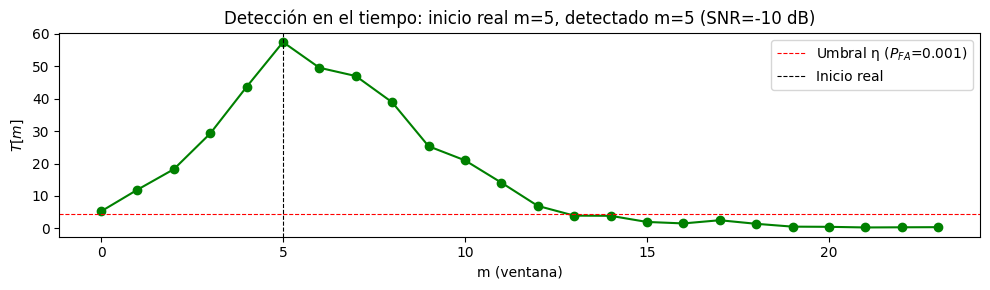

In [28]:
# Detección en el tiempo sobre el escenario
P_FA = 1e-3  # Probabilidad de falsa alarma por ventana
T = preamble_correlation(r, SF, B)
eta = time_threshold(noise_power, P_FA)
start = detect_start(T, eta)

plt.figure(figsize=(10, 3))
plt.plot(T, marker="o", color="green")
plt.axhline(eta, color="r", ls="--", lw=0.8, label=f"Umbral η ($P_{{FA}}$={P_FA})")
plt.axvline(gap, color="k", ls="--", lw=0.8, label="Inicio real")
plt.title(f"Detección en el tiempo: inicio real m={gap}, detectado m={start} (SNR={SNR_dB} dB)")
plt.xlabel("m (ventana)")
plt.ylabel("$T[m]$")
plt.legend()
plt.tight_layout()
plt.show()

### Detección en frecuencia

La estrategia en frecuencia reutiliza el demodulador (Ec. 16): cada ventana se multiplica por el *down-chirp* y se calcula su FFT. Durante el preámbulo cada ventana es un *up-chirp* de símbolo 0, por lo que el pico de la FFT aparece en el bin $q = 0$.

Mirar solo el bin 0 no aporta nada nuevo: por definición de la DFT, $D_n[0]$ es la suma de las muestras de la ventana multiplicadas por el *down-chirp*, es decir, la misma correlación $x[n] = \langle r_n, c|_{s=0} \rangle$ de la detección en el tiempo. La diferencia está en usar los $2^{SF}$ bins: el bin 0 se compara con los demás en vez de con un umbral absoluto. Una ventana "vota" por el preámbulo si el demodulador decide el símbolo $\hat{s}[n] = 0$, y el estadístico es la cantidad de votos en 8 ventanas consecutivas:

$$
V[m] = \sum_{n=m}^{m+7} \mathbb{1}\{\hat{s}[n] = 0\} \;\underset{H_0}{\overset{H_1}{\gtrless}}\; K
$$

Un umbral $K < 8$ tolera ventanas del preámbulo mal decididas por el ruido. El inicio se estima igual que en el tiempo: el máximo de $V[m]$ después del primer cruce.

- **Ventaja**: el umbral no depende de $\sigma^2$, ya que la decisión de cada ventana es relativa entre bins. Con solo ruido cada ventana vota con probabilidad $2^{-SF}$, así que la probabilidad de falsa alarma es muy baja: para $SF = 7$ y $K = 6$, $P_{FA} \approx \binom{8}{6} 2^{-42} \approx 6 \cdot 10^{-12}$.
- **Desventaja**: cada ventana toma una decisión dura con la energía de un solo símbolo, y se pierde la ganancia de 9 dB de la suma coherente. Se espera que necesite más SNR que la detección en el tiempo.
- **Empates**: con probabilidad $2^{-SF}$ la ventana de ruido justo antes del preámbulo también vota por el símbolo 0, y $V[m]$ empata en 8 con el inicio real. `detect_start` elige la primera ventana del empate, un error de $\approx 0.8\%$ que no baja con el SNR. En el tiempo no hay empates, porque $T[m]$ es continuo.

In [29]:
def preamble_votes(r: np.ndarray, SF: int, n_upchirps: int = 8) -> np.ndarray:
    """Estadístico de detección en frecuencia: votos por el símbolo 0 en ventanas consecutivas.

    Demodula cada ventana (down-chirp y FFT, Ec. 16) y cuenta cuántas de las `n_upchirps`
    ventanas a partir de m se decidieron como símbolo 0.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        np.ndarray: Estadístico V[m] (cantidad de votos) para cada ventana m donde entra el
        preámbulo completo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Demodular cada ventana de M muestras (sincronía de símbolo). Se descarta el resto
    symbols_rx = demodulator(r[: r.size // M * M], SF)

    # Voto de cada ventana: 1 si el pico de la FFT está en el bin 0, como en un up-chirp del preámbulo
    votes = (symbols_rx == 0).astype(int)

    # Suma de votos en las n_upchirps ventanas a partir de m
    return np.convolve(votes, np.ones(n_upchirps, dtype=int), mode="valid")

In [30]:
# Tests: sin ruido apreciable, el inicio detectado es el real
assert detect_start(preamble_votes(r_test, 7), 6) == 3

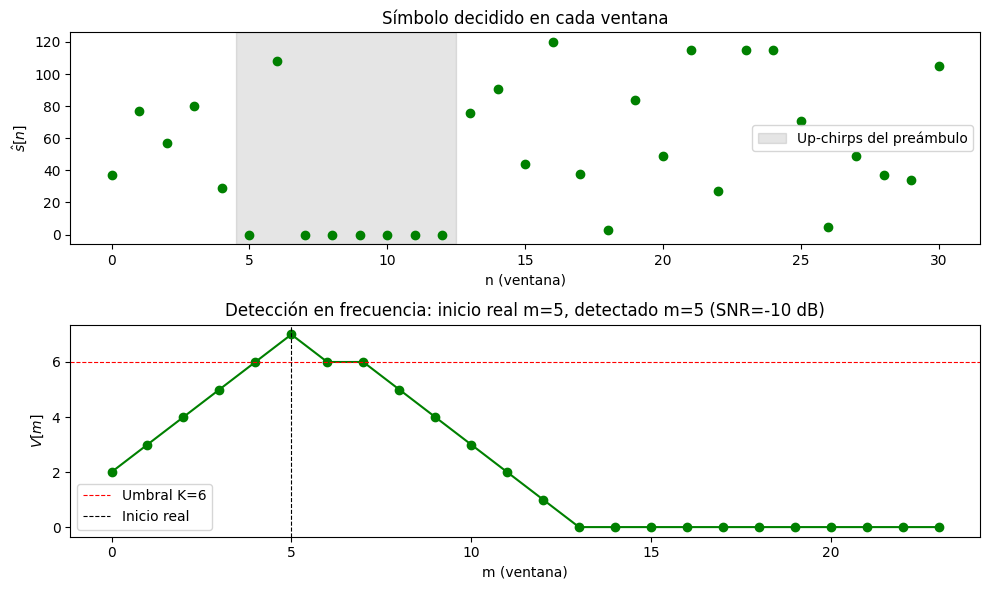

In [31]:
# Detección en frecuencia sobre el escenario
K = 6  # Votos necesarios para declarar H1: tolera 2 ventanas del preámbulo mal decididas
V = preamble_votes(r, SF)
start = detect_start(V, K)

# Símbolo decidido en cada ventana, para ver de dónde salen los votos
symbols_rx = demodulator(r[: r.size // M * M], SF)

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(symbols_rx, "o", color="green")
plt.axvspan(gap - 0.5, gap + 7.5, color="k", alpha=0.1, label="Up-chirps del preámbulo")
plt.title("Símbolo decidido en cada ventana")
plt.xlabel("n (ventana)")
plt.ylabel("$\\hat{s}[n]$")
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(V, marker="o", color="green")
plt.axhline(K, color="r", ls="--", lw=0.8, label=f"Umbral K={K}")
plt.axvline(gap, color="k", ls="--", lw=0.8, label="Inicio real")
plt.title(f"Detección en frecuencia: inicio real m={gap}, detectado m={start} (SNR={SNR_dB} dB)")
plt.xlabel("m (ventana)")
plt.ylabel("$V[m]$")
plt.legend()
plt.tight_layout()
plt.show()

### Performance de detección de la trama

Se estima, para ambas estrategias, la probabilidad de detectar el inicio de la trama en la ventana correcta en función del SNR. Una detección temprana (falsa alarma), una tardía o la no detección (*miss*) cuentan como error.

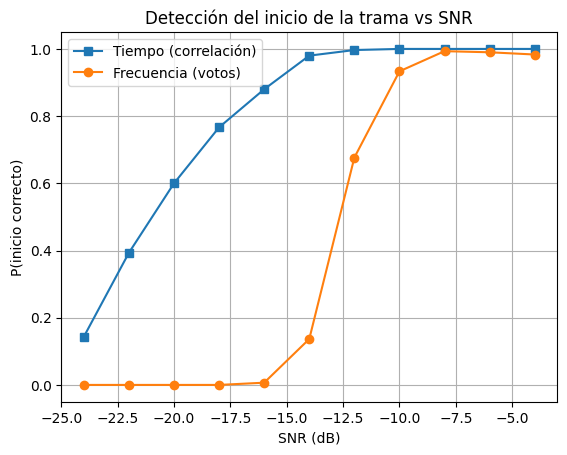

In [32]:
SF = 7
B = 125e3
gap = 5
P_FA = 1e-3
K = 6
SNRs_dB = np.arange(-24.0, -3.0, 2.0)  # -24 a -4 dB
simulations = 300  # Tramas simuladas por punto

# Fracción de tramas cuyo inicio se detecta en la ventana correcta, para cada estrategia
p_time, p_freq = [], []
for SNR_dB in SNRs_dB:
    noise_power = power(preamble(SF, B)) / 10 ** (SNR_dB / 10)
    eta = time_threshold(noise_power, P_FA)
    ok_time = ok_freq = 0
    for _ in range(simulations):
        r = transmit_frame(np.random.randint(0, 2**SF, size=16), gap, SF, B, SNR_dB, h_flat)
        ok_time += detect_start(preamble_correlation(r, SF, B), eta) == gap
        ok_freq += detect_start(preamble_votes(r, SF), K) == gap
    p_time.append(ok_time / simulations)
    p_freq.append(ok_freq / simulations)

plt.plot(SNRs_dB, p_time, marker="s", label="Tiempo (correlación)")
plt.plot(SNRs_dB, p_freq, marker="o", label="Frecuencia (votos)")
plt.title("Detección del inicio de la trama vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("P(inicio correcto)")
plt.grid(True)
plt.legend()
plt.show()

**Observaciones**:
- La detección en el tiempo funciona unos 8 dB por debajo de la detección en frecuencia (50 % de aciertos cerca de $-20$ dB contra $-12.5$ dB).
- **Integración coherente**: la detección en el tiempo suma las 8 correlaciones $x[n]$ antes del módulo, ganando $\approx 9$ dB. La detección en frecuencia juzga cada ventana por separado, con el SNR de un solo símbolo.
- **Decisión blanda contra decisión dura**: $T[m]$ conserva cuánto se parece cada ventana a un *up-chirp*, mientras que cada voto lo reduce a "símbolo 0 o no", perdiendo información.
- La detección en frecuencia es, en definitiva, demodular el preámbulo: no puede funcionar muy por debajo del SNR al que falla la demodulación. Solo la ayuda que tolera $8 - K$ ventanas mal decididas. La detección en el tiempo no decide símbolos, sino que integra la energía del preámbulo completo.
- Como se verá con el PER, este margen solo importa cuando el payload es más robusto que el preámbulo (por ejemplo, con codificación de canal o un preámbulo más corto): si no se detecta la trama, de nada sirve que el payload se pueda decodificar.

### Packet Error Rate (PER)

El BER evalúa cada bit por separado, pero en un sistema que transmite tramas la unidad útil es el paquete: si un solo bit del payload es incorrecto el paquete se descarta (en la práctica lo detecta un CRC), y si no se detecta el preámbulo se pierde el paquete entero. El *Packet Error Rate* es la fracción de paquetes recibidos con error:

$$
PER = \frac{\text{paquetes con error}}{\text{paquetes enviados}}
$$

Un paquete tiene error si ocurre cualquiera de estos eventos:

- **Miss**: no se detecta el preámbulo.
- **Inicio incorrecto** (falsa alarma, detección temprana o tardía): el payload se demodula con ventanas que no corresponden a sus símbolos.
- **Error de demodulación**: el inicio es correcto, pero algún símbolo del payload se decide mal.

Una vez detectada la ventana de inicio $\hat{m}$, el receptor conoce la estructura del preámbulo, por lo que el payload empieza $8 + 2.25$ símbolos después: en la muestra $\hat{m}\,2^{SF} + 10.25 \cdot 2^{SF}$.

Si la detección es correcta y los $N$ símbolos del payload se deciden de forma independiente con probabilidad de error de símbolo $SER$:

$$
PER = 1 - P(\text{inicio correcto})\,(1 - SER)^N
$$

El PER crece con el largo del paquete: aunque el BER sea bajo, un paquete largo tiene más oportunidades de tener algún error. Para separar el aporte de la detección del de la demodulación, se compara cada detector con una detección ideal en la que el receptor conoce el inicio de la trama: la diferencia entre las curvas es la pérdida debida a la detección.

In [33]:
def packet_error(
    r: np.ndarray, start: int | None, symbols_tx: np.ndarray, SF: int, B: float
) -> bool:
    """Determina si un paquete se recibe con error.

    Demodula el payload a partir de la ventana de inicio detectada y lo compara con el transmitido.

    Args:
        r (np.ndarray): Señal recibida.
        start (int | None): Ventana de inicio de la trama detectada, o None si no se detectó.
        symbols_tx (np.ndarray): Símbolos del payload transmitido.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.

    Returns:
        bool: True si el paquete tiene error.
    """

    # Miss: no se detectó el preámbulo, se pierde el paquete
    if start is None:
        return True

    # Chips por símbolo
    M: int = 2**SF

    # El payload empieza después del preámbulo, cuya estructura conoce el receptor
    begin = start * M + preamble(SF, B).size
    payload = r[begin : begin + symbols_tx.size * M]

    # Detección tardía: el payload queda fuera de la señal recibida
    if payload.size < symbols_tx.size * M:
        return True

    # Basta un símbolo incorrecto para descartar el paquete
    # Comparar símbolos equivale a comparar bits: el codificador es una biyección
    return not np.array_equal(demodulator(payload, SF), symbols_tx)

In [34]:
# Tests: sin ruido apreciable, el paquete se recibe sin errores solo con el inicio correcto
symbols_test = np.random.randint(0, 2**7, size=8)
r_test = transmit_frame(symbols_test, 3, 7, 125e3, 100, np.array([1.0]))
assert not packet_error(r_test, 3, symbols_test, 7, 125e3)
assert packet_error(r_test, 2, symbols_test, 7, 125e3)
assert packet_error(r_test, None, symbols_test, 7, 125e3)

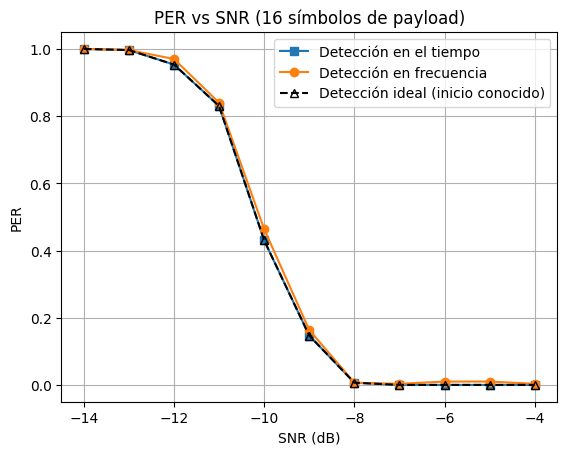

In [35]:
SF = 7
B = 125e3
gap = 5
P_FA = 1e-3
K = 6
num_symbols = 16  # Símbolos del payload por paquete
SNRs_dB = np.arange(-14.0, -3.0, 1.0)  # -14 a -4 dB
simulations = 300  # Paquetes simulados por punto

# PER para la detección ideal (inicio conocido) y para cada estrategia de detección
per_ideal, per_time, per_freq = [], [], []
for SNR_dB in SNRs_dB:
    noise_power = power(preamble(SF, B)) / 10 ** (SNR_dB / 10)
    eta = time_threshold(noise_power, P_FA)
    errors_ideal = errors_time = errors_freq = 0
    for _ in range(simulations):
        symbols_tx = np.random.randint(0, 2**SF, size=num_symbols)
        r = transmit_frame(symbols_tx, gap, SF, B, SNR_dB, h_flat)
        errors_ideal += packet_error(r, gap, symbols_tx, SF, B)
        start_time = detect_start(preamble_correlation(r, SF, B), eta)
        errors_time += packet_error(r, start_time, symbols_tx, SF, B)
        start_freq = detect_start(preamble_votes(r, SF), K)
        errors_freq += packet_error(r, start_freq, symbols_tx, SF, B)
    per_ideal.append(errors_ideal / simulations)
    per_time.append(errors_time / simulations)
    per_freq.append(errors_freq / simulations)

# Escala lineal: en escala logarítmica no se verían los puntos con PER = 0
plt.plot(SNRs_dB, per_time, marker="s", label="Detección en el tiempo")
plt.plot(SNRs_dB, per_freq, marker="o", label="Detección en frecuencia")
# La detección ideal se dibuja última, punteada y con marcadores huecos, para que se vea aunque
# coincida con alguna de las otras curvas
plt.plot(
    SNRs_dB,
    per_ideal,
    marker="^",
    mfc="none",
    color="k",
    ls="--",
    label="Detección ideal (inicio conocido)",
)
plt.title(f"PER vs SNR ({num_symbols} símbolos de payload)")
plt.xlabel("SNR (dB)")
plt.ylabel("PER")
plt.grid(True)
plt.legend()
plt.show()

**Observaciones**:
- La detección no es el cuello de botella: la detección en el tiempo encuentra el inicio en todos los paquetes desde $-12$ dB, mientras que el payload necesita unos $-8$ dB para que los $N = 16$ símbolos se decidan bien. Su curva coincide con la de detección ideal (punteada).
- La detección en frecuencia solo se aparta de la ideal cerca de $-10$ dB, donde todavía falla en algunos paquetes, y en el piso de $\approx 0.8\%$ por empates.
- El preámbulo es más robusto que el payload porque la detección acumula información de 8 símbolos (o tolera ventanas erradas con $K < 8$), mientras que el payload exige que todos sus símbolos se decidan bien.

## Detección de la trama en un canal selectivo en frecuencia

Se repite el análisis de la detección de la trama, ahora con el canal con eco `h_freq_sel` definido en la sección de detección con ruido en un canal selectivo en frecuencia. Es el canal multicamino de energía unitaria que usa el paper en la Sec. IV para la curva "Freq.Sel FSCM" de Fig. 1:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$

La señal recibida es la suma del camino directo y de un eco retrasado una muestra. Como $|h|^2 = 1$, el canal no cambia la potencia de la señal: el SNR es el mismo que en el canal plano, pero el 20 % de la energía llega por el eco.

**El eco después del down-chirp**: ignorando el módulo de la Ec. 2, un símbolo $s$ es $c(k) = \frac{1}{\sqrt{2^{SF}}} e^{j2\pi \frac{(s+k)k}{2^{SF}}}$. El eco $c(k-1)$ multiplicado por el *down-chirp* queda

$$
c(k-1)\, e^{-j2\pi \frac{k^2}{2^{SF}}} \propto e^{\,j2\pi \frac{(s-2)k}{2^{SF}}}
$$

una exponencial compleja de frecuencia constante, igual que el camino directo pero desplazada dos *bins*: el eco aparece en la FFT del demodulador como un segundo pico en $q = s - 2$ con el 20 % de la energía. Un retardo en el tiempo es un corrimiento en frecuencia del *chirp*.

Esto afecta de forma distinta a cada estrategia de detección:

- **Tiempo**: la correlación con el *up-chirp* es el bin 0 de la FFT, y el eco cae en el bin $-2$, ortogonal. El eco no interfiere, pero su energía se pierde: el pico de $T[m]$ baja a $0.8 \cdot 8^2 \approx 51$, una pérdida de $10\log_{10} 0.8 \approx 1$ dB.
- **Frecuencia** y **demodulación del payload**: además de perder el 20 % de la energía, el pico del eco compite con el correcto. Con ruido, el bin $s - 2$ supera al bin $s$ mucho más seguido que cualquier otro bin, y el demodulador decide $\hat{s} = s - 2$.

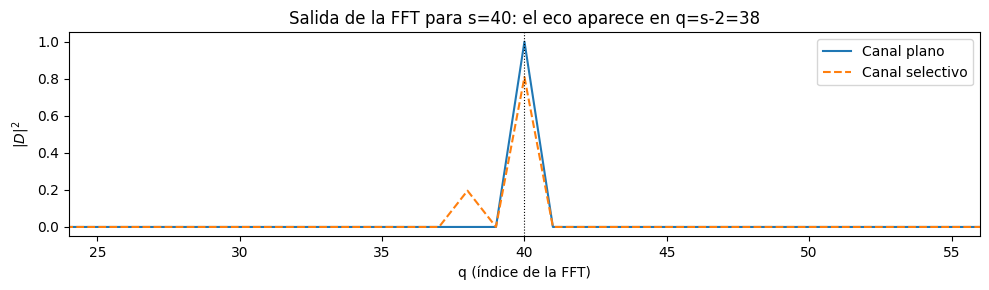

In [36]:
# Salida de la FFT del demodulador para un símbolo, sin ruido, en ambos canales
SF = 7
B = 125e3
M = 2**SF
s = 40
# Se demodula el segundo símbolo: el primero aporta el eco de su última muestra, como en una trama
c = modulator(np.array([0, s]), SF, B)

plt.figure(figsize=(10, 3))
for h, name, style in [(h_flat, "Canal plano", "-"), (h_freq_sel, "Canal selectivo", "--")]:
    r = system(c, h, np.zeros_like(c))
    D = np.fft.fft(r[M:] * np.exp(-1j * 2 * np.pi * np.arange(M) ** 2 / M), norm="ortho")
    plt.plot(np.abs(D) ** 2, ls=style, label=name)
plt.axvline(s, color="k", ls=":", lw=0.8)
plt.title(f"Salida de la FFT para s={s}: el eco aparece en q=s-2={s - 2}")
plt.xlabel("q (índice de la FFT)")
plt.ylabel("$|D|^2$")
plt.xlim(s - 16, s + 16)
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
def frame_performance(
    h: np.ndarray,
    SNRs_dB: np.ndarray,
    SF: int,
    B: float,
    gap: int,
    P_FA: float,
    K: int,
    num_symbols: int,
    simulations: int,
) -> dict[str, np.ndarray]:
    """Estima la detección del inicio de la trama y el PER en función del SNR para un canal.

    Para cada SNR simula `simulations` tramas y evalúa la detección en el tiempo, la detección
    en frecuencia y la detección ideal (inicio conocido).

    Args:
        h (np.ndarray): Respuesta al impulso del canal.
        SNRs_dB (np.ndarray): Relaciones señal-ruido a simular, en decibelios.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        gap (int): Cantidad de símbolos de silencio antes de la trama.
        P_FA (float): Probabilidad de falsa alarma por ventana de la detección en el tiempo.
        K (int): Votos necesarios para declarar H1 en la detección en frecuencia.
        num_symbols (int): Símbolos del payload por paquete.
        simulations (int): Paquetes simulados por punto.

    Returns:
        dict[str, np.ndarray]: Fracción de inicios correctos (`p_time`, `p_freq`) y PER
        (`per_ideal`, `per_time`, `per_freq`) para cada SNR.
    """

    results = {key: [] for key in ["p_time", "p_freq", "per_ideal", "per_time", "per_freq"]}
    for SNR_dB in SNRs_dB:
        noise_power = power(preamble(SF, B)) / 10 ** (SNR_dB / 10)
        eta = time_threshold(noise_power, P_FA)
        ok_time = ok_freq = errors_ideal = errors_time = errors_freq = 0
        for _ in range(simulations):
            symbols_tx = np.random.randint(0, 2**SF, size=num_symbols)
            r = transmit_frame(symbols_tx, gap, SF, B, SNR_dB, h)
            start_time = detect_start(preamble_correlation(r, SF, B), eta)
            start_freq = detect_start(preamble_votes(r, SF), K)
            ok_time += start_time == gap
            ok_freq += start_freq == gap
            errors_ideal += packet_error(r, gap, symbols_tx, SF, B)
            errors_time += packet_error(r, start_time, symbols_tx, SF, B)
            errors_freq += packet_error(r, start_freq, symbols_tx, SF, B)
        results["p_time"].append(ok_time / simulations)
        results["p_freq"].append(ok_freq / simulations)
        results["per_ideal"].append(errors_ideal / simulations)
        results["per_time"].append(errors_time / simulations)
        results["per_freq"].append(errors_freq / simulations)

    return {key: np.array(values) for key, values in results.items()}

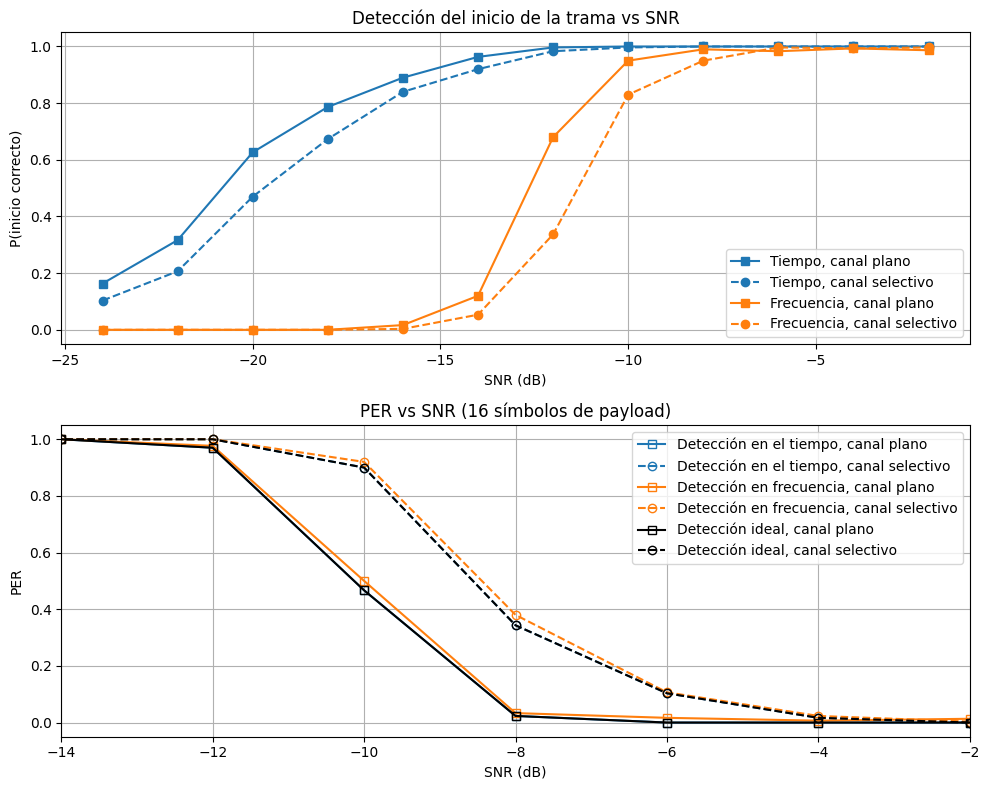

In [38]:
SF = 7
B = 125e3
gap = 5
P_FA = 1e-3
K = 6
num_symbols = 16  # Símbolos del payload por paquete
SNRs_dB = np.arange(-24.0, -1.0, 2.0)  # -24 a -2 dB
simulations = 300  # Paquetes simulados por punto

params = (SNRs_dB, SF, B, gap, P_FA, K, num_symbols, simulations)
flat = frame_performance(h_flat, *params)
freq_sel = frame_performance(h_freq_sel, *params)

# Mismo color para cada estrategia: línea llena para el canal plano y punteada para el selectivo
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
for key, name, color in [("p_time", "Tiempo", "C0"), ("p_freq", "Frecuencia", "C1")]:
    plt.plot(SNRs_dB, flat[key], marker="s", color=color, label=f"{name}, canal plano")
    plt.plot(
        SNRs_dB, freq_sel[key], marker="o", color=color, ls="--", label=f"{name}, canal selectivo"
    )
plt.title("Detección del inicio de la trama vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("P(inicio correcto)")
plt.grid(True)
plt.legend()
plt.subplot(2, 1, 2)
for key, name, color in [
    ("per_time", "Detección en el tiempo", "C0"),
    ("per_freq", "Detección en frecuencia", "C1"),
    ("per_ideal", "Detección ideal", "k"),
]:
    plt.plot(SNRs_dB, flat[key], marker="s", mfc="none", color=color, label=f"{name}, canal plano")
    plt.plot(
        SNRs_dB,
        freq_sel[key],
        marker="o",
        mfc="none",
        color=color,
        ls="--",
        label=f"{name}, canal selectivo",
    )
plt.title(f"PER vs SNR ({num_symbols} símbolos de payload)")
plt.xlabel("SNR (dB)")
plt.ylabel("PER")
plt.xlim(-14, SNRs_dB[-1])  # Por debajo de -14 dB el PER es 1 en todos los casos
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

**Observaciones**:
- **Detección**: las dos estrategias pierden poco más de 1 dB respecto del canal plano. En el tiempo es la energía del eco, que no entra en la correlación con el *up-chirp*. En frecuencia el corrimiento es algo mayor, porque el pico del eco en el bin $-2$ además le roba votos al bin 0.
- **Payload**: el PER se corre unos 2.5 dB, más que la detección. Es la misma pérdida que muestra Fig. 1 del paper entre las curvas "Flat FSCM" y "Freq.Sel FSCM" del BER. Cada símbolo del payload compite contra su propio eco en $s - 2$ y, a SNR alto, la mayoría de los errores de símbolo son justamente $\hat{s} = s - 2$.
- La detección sigue sin ser el cuello de botella: la curva de la detección en el tiempo coincide con la de detección ideal también en el canal selectivo. El eco perjudica más a la demodulación que a la detección.
- **Próximos pasos**: si el receptor conoce (o estima) $h$, puede recuperar la energía del eco combinando los bins $q$ y $q - 2$ de la FFT, o correlando con el preámbulo filtrado por el canal $h * p$ (filtro adaptado al canal).